# Modelado experimental



## Criterios de evaluación y selección de modelos

Tal como se definió en los criterios de evaluación, y con el objetivo de conectar el rendimiento predictivo con los requerimientos y las necesidades del negocio, se utilizará la métrica MAPE (error porcentual absoluto medio) como criterio principal para evaluar el modelo destinado a realizar las predicciones. Asimismo, se considerará el trade-off sesgo-varianza para verificar que el modelo seleccionado presente un comportamiento estable y una adecuada capacidad de generalización.

En este contexto, y considerando el alcance de los entregables, no se priorizarán la interpretabilidad ni la posible latencia en producción.



## Librerías

In [94]:
import os
import sys
import warnings

warnings.filterwarnings(
    "ignore",
    category=Warning,
    module="pandas",
)

# Agrega el directorio padre (raíz del proyecto) al path de Python
sys.path.append(os.path.abspath(os.path.join('..')))

In [95]:
import pprint

In [96]:
import joblib

In [97]:
# ============================================================
# 1. MANIPULACIÓN Y ANÁLISIS DE DATOS
# ============================================================

import numpy as np
import pandas as pd

In [98]:
# ============================================================
# 2. VISUALIZACIÓN DE DATOS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import graphviz
from IPython.display import Image

In [99]:
# ============================================================
# 3. Pruebas estadisticas
# ============================================================

import scipy.stats as stats
from sklearn.feature_selection import chi2
from scipy.stats import chi2_contingency

In [100]:
# ============================================================
# 4. MODELOS DE MACHINE LEARNING
# ============================================================
from sklearn.linear_model import ElasticNet

from sklearn.ensemble import (
    RandomForestRegressor,
)

from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor

from sklearn.tree import (
    DecisionTreeRegressor,
    plot_tree,
    export_text,
    export_graphviz,
    _tree
)

In [101]:
# ============================================================
# 5. SELECCIÓN, VALIDACIÓN Y AJUSTE DE MODELOS
# ============================================================

from sklearn.base import clone

from sklearn.pipeline import Pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer

from src.cronological_split import chronological_panel_train_test_split, ChronologicalPanelSplitCV

from src.experiment_factory import ExperimentFactory
from src.model_optimizer import ModelOptimizer
from src.experiment_evaluator import ExperimentEvaluator
from src.experiment_tracker import ExperimentTracker
from sklearn.metrics import mean_absolute_percentage_error, make_scorer

In [102]:
# ============================================================
# 9. FUNCIONES Y TRANSFORMACIONES PROPIAS
# ============================================================

from src.custom_standarization_classes_and_functions import GeneralPreprocessor



## Funciones complementarias



In [103]:
# Define funciones nombradas (globales)
def get_week_of_year(x):
    return x.dt.isocalendar().week.astype(int)

def get_quarter(x):
    return x.dt.quarter

def get_is_weekend(x):
    return (x.dt.dayofweek >= 5).astype('category')

def get_month(x):
    return x.dt.month.astype('category')

In [104]:
def convert_to_array(X):
    return np.asarray(X)

## Importación de datos



In [105]:
df_ml_path = '../data/1_bronze/df.csv'
df_ml = pd.read_csv(df_ml_path)
df_ml.sample(5)

,Unnamed: 0,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
270182,270182,298,2,2014-02-18,8903,666,1,1,0,0,d,a,19840.0,7.0,2009.0,0,NaN,NaN,NaN
295202,295202,325,6,2014-04-05,4506,432,1,0,0,0,a,c,350.0,3.0,2011.0,1,22.0,2011.0,"Feb,May,Aug,Nov"
826545,826545,907,3,2013-03-06,5734,885,1,1,0,0,a,c,250.0,NaN,NaN,0,NaN,NaN,NaN
441747,441747,484,4,2014-01-16,5322,581,1,0,0,0,a,c,14300.0,3.0,2011.0,0,NaN,NaN,NaN
928646,928646,1019,3,2015-06-10,5564,522,1,0,0,0,d,c,2740.0,7.0,2014.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"


> Los días donde las tiendas estan cerradas, las ventas son 0, por ende, se filtrara el DataFrame por esta variable.

In [106]:
store_open = df_ml['Open'] == 1
df_ml = df_ml[store_open]
df_ml.sample(n=5)

,Unnamed: 0,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
775900,775900,852,6,2015-01-10,2800,338,1,0,0,0,c,a,940.0,4.0,2004.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
535849,535849,588,1,2014-07-21,5453,614,1,0,0,1,d,c,15720.0,3.0,2010.0,0,NaN,NaN,NaN
447959,447959,491,4,2014-01-30,4907,419,1,0,0,0,d,c,4680.0,NaN,NaN,1,22.0,2012.0,"Mar,Jun,Sept,Dec"
10360,10360,11,3,2013-01-02,8913,1402,1,0,0,1,a,c,960.0,11.0,2011.0,1,1.0,2012.0,"Jan,Apr,Jul,Oct"
617787,617787,679,2,2015-05-05,10743,1079,1,1,0,0,a,a,4140.0,9.0,2012.0,0,NaN,NaN,NaN


### Separación de datos


In [107]:
#top_columns = joblib.load('../artifacts/top_columns.joblib')
#top_columns


#### `X` e `y` y conjuntos de entrenamiento y prueba (`train`-`test`)


In [108]:
X_train, X_test, y_train, y_test = chronological_panel_train_test_split(
    df_ml, 
    target_col= 'Sales',
    test_days=None, 
    test_size=0.3, 
    filter_open_train=False
)

[ChronologicalPanelSplit] Fecha de corte: 2014-10-22
Train: 2013-01-01 -> 2014-10-22 | Shape X: (594533, 18)
Test:  2014-10-23 -> 2015-07-31 | Shape X: (249859, 18)


Samples:

In [109]:
#SAMPLE_SIZE = min(50000, len(X_train))
#X_train = X_train.sample(n=SAMPLE_SIZE, random_state=42)
#y_train = y_train.loc[X_train.index]



## Instanciación y creación de la grilla de hiperparámetros mediante `GridSearchCV`


Se probara un modelo robusto y capaces de capturar relaciones lineales y no lineales, así como robustez ante la varianza y sesgo.

### Métodos de reducción

In [110]:
reductions = {
    "options": {
        "Sin reducción": "passthrough",
    },

    "grids": {
        "Sin reducción": {},
    }
}

### Modelos avanzados: ensamblados y redes neuronales

* XGBoost
* MLP

#### XGBoost


In [111]:
xgboost = XGBRegressor(
    random_state=42,
    objective="reg:squarederror",
    eval_metric="rmse",
    n_jobs=1,
    verbosity=0
)

grid_xgboost = {
    "n_estimators": [500, 800],
    "max_depth": [3, 5],
    "learning_rate": [0.03, 0.05],
    "min_child_weight": [5, 10],
    "gamma": [0.1, 0.5],
    "subsample": [0.8],
    "colsample_bytree": [0.8],
    "reg_lambda": [5, 10],
    "reg_alpha": [0.1, 1]
}

#### MLP


In [112]:
mlp = MLPRegressor(
    max_iter=500,
    early_stopping=True,
    random_state=42
)
grid_mlp = {
    "hidden_layer_sizes": [
        (50,),
        (100,),
        (100, 50)
    ],
    "activation": ["relu", "tanh"],
    "alpha": [0.0001, 0.001, 0.01],
    "learning_rate_init": [0.001, 0.01]
}

### Combinaciones de modelos y grillas de hiperparámetros


In [113]:
models = {
    "options": {
        "XGBR": xgboost,
        #"MLP": mlp
    },

    "grids": {
        "XGBR": grid_xgboost,
        #"MLP": grid_mlp
    },
}

#### Carga de artefactos


In [114]:
preprocessor = joblib.load('../artifacts/pipeline_preprocessing_fe.joblib')

#### Pipeline


Columnas con mayor importancia de características (`feature importance`) en iteraciones previas:


In [115]:
columns = [
    'promo',
    'assortment',
    'promo2',
    'promo2sinceyear',
    'storetype_b',
    'storetype_a',
    'storetype_d',
    'storetype_c',
    'store',
    'dayofweek',
    'month',
    'competitiondistance',
    'competitionopensincemonth'
]

Construcción del pipeline final:

In [116]:
pipeline_ml = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("selection", ColumnTransformer(
        transformers=[
            ("select", "passthrough", columns)
        ],
        remainder="drop",
        verbose_feature_names_out=False
    )),
    ("reduction", "passthrough"),
    ("model", clone(xgboost))
])

### Combinaciones de experimentos: estrategias de reducción de dimensionalidad × estrategias de modelado × hiperparámetros

In [117]:
factory = ExperimentFactory(
    models=models,
    reductions=reductions,
)

experiments = factory.generate()

for experiment in experiments:
    print(f"Modelo: {experiment['nombre_modelo']}")
    print(f"Reducción: {experiment['reduccion']}")
    print(f"Grid: {experiment['param_grid']}")
    print("-" * 60)

Modelo: XGBR
Reducción: Sin reducción
Grid: {'model__n_estimators': [500, 800], 'model__max_depth': [3, 5], 'model__learning_rate': [0.03, 0.05], 'model__min_child_weight': [5, 10], 'model__gamma': [0.1, 0.5], 'model__subsample': [0.8], 'model__colsample_bytree': [0.8], 'model__reg_lambda': [5, 10], 'model__reg_alpha': [0.1, 1], 'reduction': ['passthrough'], 'model': [XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             

### Entrenamiento y optimización con `GridSearchCV`

In [118]:
cv = ChronologicalPanelSplitCV(
    n_splits=5,
    test_size=30,
    min_train_size=180,
    date_col='Date',
    gap=0,
    verbose=False
)

In [ ]:
scoring = {
    #"r2": "r2",
    "mae": "neg_mean_absolute_error",
    #"rmse": "neg_root_mean_squared_error",
}


optimizer = ModelOptimizer(
    pipeline=pipeline_ml,
    cv=5,
    scoring=scoring,
    refit="mae",
    search_type="random",
    n_iter=30,
    random_state=42,
    n_jobs=-1,
    verbose=0,
)

# comentado para evitar reentrenamiento en futuras iteraciones

optimizer.fit(
    experiments=experiments,
    X=X_train,
    y=y_train
)

### Evaluación general

In [120]:
results = optimizer.get_results()

In [121]:
# lectura de resultados de iteraciones anteriores

#results = pd.read_csv('../models/results.csv')

In [122]:
display(results.style.format("{:.2f}", subset=results.select_dtypes(include='number').columns))

,Modelo,Reducción,Método búsqueda,Score medio validación CV: mae,Score medio entrenamiento CV: mae,Desviación estándar validación CV: mae,Brecha score entrenamiento-validación CV: mae,Mejores parámetros
0,XGBR,Sin reducción,random,-917.79,-753.70,153.30,164.10,"{'reduction': 'passthrough', 'model__subsample': 0.8, 'model__reg_lambda': 5, 'model__reg_alpha': 1, 'model__n_estimators': 800, 'model__min_child_weight': 5, 'model__max_depth': 5, 'model__learning_rate': 0.05, 'model__gamma': 0.5, 'model__colsample_bytree': 0.8, 'model': XGBRegressor(base_score=None, booster=None, callbacks=None, colsample_bylevel=None, colsample_bynode=None, colsample_bytree=None, device=None, early_stopping_rounds=None, enable_categorical=True, eval_metric='rmse', feature_types=None, feature_weights=None, gamma=None, grow_policy=None, importance_type=None, interaction_constraints=None, learning_rate=None, max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None, max_delta_step=None, max_depth=None, max_leaves=None, min_child_weight=None, missing=nan, monotone_constraints=None, multi_strategy=None, n_estimators=None, n_jobs=1, num_parallel_tree=None, ...)}"


---

### Pipeline `XGBRegressor`

In [123]:
# comentado para evitar reentrenamiento en futuras iteraciones

pipeline_xgb_sin_reduccion = optimizer.search_objects['XGBR', 'Sin reducción'].best_estimator_
pipeline_xgb_sin_reduccion

#pipeline_xgb_sin_reduccion = joblib.load('../models/pipeline_xgb_sin_reduccion.joblib')

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('selection', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['Unnamed: 0','Store','DayOfWeek',...,'Promo2SinceWeek','Promo2SinceYear', 'PromoInterval']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('gp_step', ...), ('general_preprocessing', ...), ...]"
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",True
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline canno

In [124]:
xgbr_sin_reduccion = pipeline_xgb_sin_reduccion.named_steps['model']

#### Evaluación individual

Durante el entrenamiento:


<Axes: >

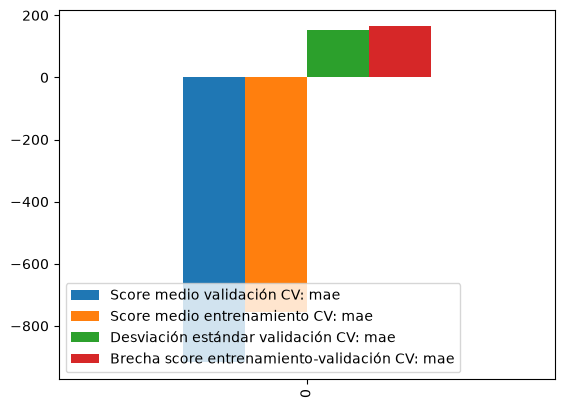

In [126]:
results[(results['Modelo']=='XGBR') & (results['Reducción']=='Sin reducción')].plot(kind='bar')

Con métrica externa:


In [127]:
# predicciones sobre test

y_pred_test = pipeline_xgb_sin_reduccion.predict(X_test)
y_pred_test

/var/folders/sf/zv8w99hn1570688_wf9y1h280000gn/T/ipykernel_75894/950236481.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return (x.dt.dayofweek >= 5).astype('category')


array([ 5463.6035, 10068.146 ,  6550.644 , ...,  7412.5713,  7248.5996,
        4885.357 ], shape=(249859,), dtype=float32)

In [128]:
# MAPE sobre test

mape = mean_absolute_percentage_error(y_test, y_pred_test)

print(np.round(mape * 100, 3))

4.2577789190144e+16


> Debido a la presencia de valores iguales a cero en la variable objetivo (correspondientes a los días en que las tiendas permanecen cerradas), el MAPE (Mean Absolute Percentage Error) no resulta una métrica adecuada para evaluar el modelo, ya que presenta indefiniciones o valores extremadamente elevados al calcular errores porcentuales sobre observaciones nulas o cercanas a cero. Esto puede distorsionar los resultados y reducir su representatividad respecto del desempeño real del modelo.
> 
> Por este motivo, se optará por utilizar métricas alternativas y complementarias:
>
> * NMAE (Normalized Mean Absolute Error): error absoluto medio normalizado por la media de los valores reales de la variable objetivo.
> * WAPE (Weighted Absolute Percentage Error): error absoluto total expresado como proporción del volumen total real, permitiendo evaluar el error porcentual agregado.
> * R² (Coeficiente de determinación): mide la proporción de la variabilidad de la variable objetivo explicada por el modelo.

In [129]:
r2 = r2_score(y_test, y_pred_test)

print('R2:',np.round(r2, 3))

R2: 0.812


In [130]:
mae = mean_absolute_error(y_test, y_pred_test)

print('MAE:',np.round(mae, 3))

MAE: 941.968


In [131]:
wape = (
    np.sum(np.abs(y_test - y_pred_test))
    / np.sum(np.abs(y_test))
)

print(f"WAPE: {wape * 100:.3f}%")

WAPE: 12.993%


In [132]:
nmae = (
    mae
    / np.mean(np.abs(y_test))
)

print(f"NMAE: {nmae * 100:.3f}%")

NMAE: 12.993%


In [133]:
def calculate_metrics(group):

    y_test = group['y_test']
    y_pred = group['y_pred']

    r2 = r2_score(y_test, y_pred) if len(y_test) > 1 else np.nan

    mae = mean_absolute_error(y_test, y_pred)

    wape = (
        np.sum(np.abs(y_test - y_pred))
        / np.sum(np.abs(y_test))
    ) if np.sum(np.abs(y_test)) != 0 else np.nan

    nmae = (
        mae / np.mean(np.abs(y_test))
    ) if np.mean(np.abs(y_test)) != 0 else np.nan

    return pd.Series({
        'R2': r2,
        'MAE': mae,
        'WAPE': wape * 100,
        'NMAE': nmae * 100
    })

In [134]:
df_eval = pd.DataFrame({
    'Store': df_ml.loc[X_test.index, 'Store'],
    'y_test': y_test,
    'y_pred': y_pred_test
})

metrics_store = (
    df_eval
    .groupby('Store')
    .apply(calculate_metrics)
    .reset_index()
)

metrics_store.head()

,Store,R2,MAE,WAPE,NMAE
0,1,0.383677,636.991455,13.286932,13.286931
1,2,0.747074,598.242615,11.633027,11.633026
2,3,0.712334,761.327271,10.770002,10.770002
3,4,0.260663,1126.052612,11.159590,11.159589
4,5,0.822611,495.881958,10.314998,10.314998


##### Interpretabilidad individual


In [135]:
nombres_variables = (

    pipeline_xgb_sin_reduccion
    .named_steps["selection"]
    .get_feature_names_out()

)

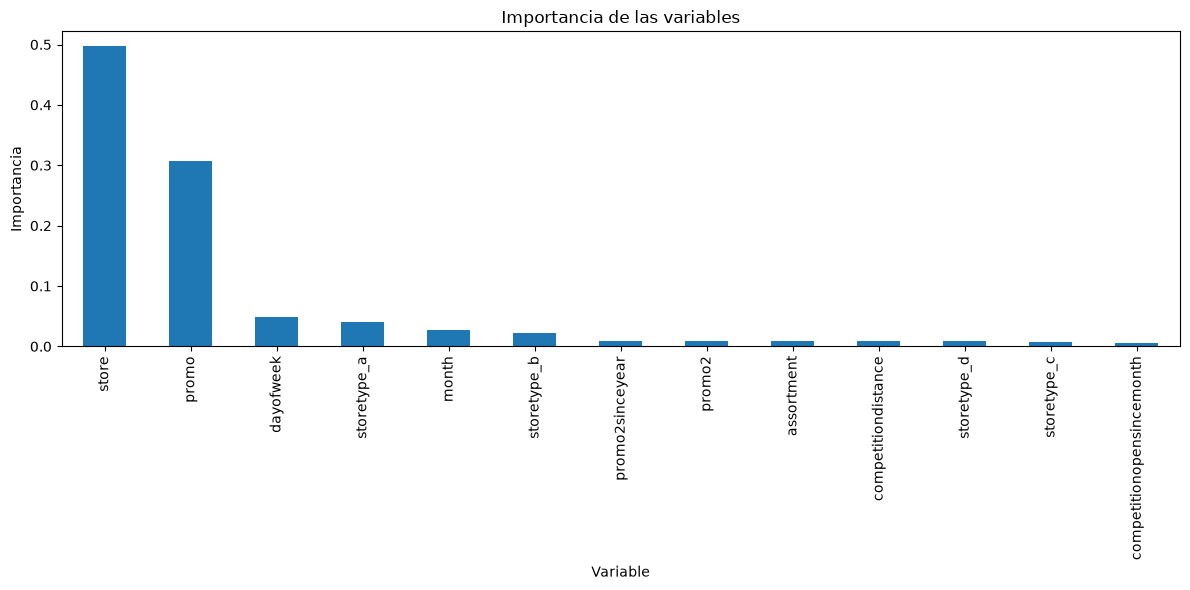

In [136]:
feature_importance = pd.DataFrame({
    "Variable": nombres_variables,
    "Importancia": xgbr_sin_reduccion.feature_importances_,
}).sort_values(
    "Importancia",
    ascending=False,
)

feature_importance.plot(
    kind='bar',
    x='Variable',
    y='Importancia',
    figsize=(12, 6),
    legend=False
)

plt.xticks(rotation=90)
plt.ylabel('Importancia')
plt.title('Importancia de las variables')
plt.tight_layout()
plt.show()

##### Predicciones a entregar (últimos 60 días)

In [164]:
sales_60 = pd.Series(name='Sales', data=y_pred_test, index=y_test.index)
df_y_pred_60 = pd.DataFrame(data=sales_60, index=y_test.index)
df_y_pred_60 = pd.concat([X_test.loc[y_test.index][['Date', 'Store']], df_y_pred_60], axis=1)
df_y_pred_60

,Date,Store,Sales
240321,2014-10-23,265,5463.603516
286707,2014-10-23,316,10068.146484
294059,2014-10-23,324,6550.644043
1008438,2014-10-23,1106,5042.600586
615339,2014-10-23,676,7271.175781
...,...,...,...
718008,2015-07-31,789,3479.381836
248518,2015-07-31,274,3872.562988
247576,2015-07-31,273,7412.571289
630704,2015-07-31,693,7248.599609


### Pipeline `DecisionTreeClassifier`


Análisis diagnostico complementario: discretización de la variable objetivo y árbol de clasificación

> Como análisis complementario al problema de regresión, se plantea discretizar la variable objetivo y entrenar un árbol de clasificación con el propósito de explorar posibles reglas de decisión y patrones asociados a distintos niveles de ventas.
> 
> Este procedimiento busca facilitar explicavilidad, y la identificación de combinaciones de características que permitan caracterizar diferentes segmentos de la variable objetivo. 
> 
> Se trata de un análisis diagnostico en desarrollo, que no forma parte de los entregables obligatorios ni interviene en la selección del modelo predictivo final.

Discretización y modelado:

In [ ]:
""" from sklearn.tree import DecisionTreeClassifier """

In [ ]:
""" # Calcular cuartiles exclusivamente con entrenamiento
quantiles = y_train.quantile([0.25, 0.50, 0.75])

# Construir límites
bins = [
    -np.inf,
    quantiles.loc[0.25],
    quantiles.loc[0.50],
    quantiles.loc[0.75],
    np.inf
]

labels = [
    "Ventas bajas",
    "Ventas medias-bajas",
    "Ventas medias-altas",
    "Ventas altas"
]

# Discretizar target de entrenamiento y test
y_train_class = pd.cut(
    y_train,
    bins=bins,
    labels=labels,
    include_lowest=True
)

y_test_class = pd.cut(
    y_test,
    bins=bins,
    labels=labels,
    include_lowest=True
) """

In [ ]:
""" 

decision_tree = DecisionTreeClassifier(
    random_state=42
)

grid_decision_tree = {

    # Profundidad: controlar la complejidad del árbol
    "max_depth": [3, 4, 5],

    # Mínimo de observaciones para dividir un nodo
    "min_samples_split": [0.05, 0.10],

    # Mínimo de observaciones por hoja
    "min_samples_leaf": [0.05, 0.10],

    # Cantidad máxima de hojas
    "max_leaf_nodes": [6, 8],

    # Poda: evitar reglas demasiado específicas
    "ccp_alpha": [0.0, 0.001],

    # Criterio de división
    "criterion": ["gini"],

    # Sin balanceo inicialmente
    "class_weight": [None]
}


reductions = {
    "options": {
        "Sin reducción": "passthrough",
    },

    "grids": {
        "Sin reducción": {},
    }
}


models = {
    "options": {
        "DTC": decision_tree,
    },

    "grids": {
        "DTC": grid_decision_tree,
    },
}


pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),

    ("selection", ColumnTransformer(
        transformers=[
            ("select", "passthrough", columns)
        ],
        remainder="drop",
        verbose_feature_names_out=False
    )),

    ("reduction", "passthrough"),

    ("model", clone(decision_tree))
])


# Métrica de evaluación
scoring = {
    "f1": "f1_macro",
}


# Generación de experimentos
factory = ExperimentFactory(
    models=models,
    reductions=reductions,
)

experiments = factory.generate()


# Validación cruzada
cv = ChronologicalPanelSplitCV(
    n_splits=5,
    test_size=30,
    min_train_size=180,
    date_col="Date",
    gap=0,
    verbose=False
)


# Optimización
optimizer = ModelOptimizer(
    pipeline=pipeline,
    cv=cv,
    scoring=scoring,
    refit="f1",
    search_type="random",
    n_iter=30,
    random_state=42,
    n_jobs=-1,
    verbose=0,
)


optimizer.fit(
    experiments=experiments,
    X=X_train,
    y=y_train
) """

#### Evaluación individual


Durante el entrenamiento:


Con métrica externa:


##### Interpretabilidad individual


Importancia de las variables:


In [ ]:
""" X_train_clasif = pipeline_decision_tree_sin_reduccion.named_steps['preprocessor'].transform(X_train)
X_test_clasif = pipeline_decision_tree_sin_reduccion.named_steps['preprocessor'].transform(X_test) """

Reglas de decisión obtenidas mediante el árbol de clasificación:

Esquema de reglas:

### Guardado del mejor modelo

#### Resultados de los modelos durante el entrenamiento con validación cruzada


In [ ]:
results.to_csv('../models/results.csv')

#### Árbol interpretable


Pipeline completo:


#### Ensemble de XGBoost con las mejores métricas


Pipeline completo:

In [138]:

# Guardar el modelo entrenado en un archivo .pkl
path_best_ml_model_pipeline = '../models/pipeline_xgb_sin_reduccion.joblib'
joblib.dump(pipeline_xgb_sin_reduccion, path_best_ml_model_pipeline)

['../models/pipeline_xgb_sin_reduccion.joblib']

Capacidad predictiva por tienda:

In [167]:
metrics_store.to_csv('../deliverables/predictive_confidence_by_store.csv')

Predicciones últimos 60 días:

In [166]:
df_y_pred_60.to_csv('../deliverables/Rossmann_Sales_Forecast.csv')

---